# Decision Trees and Random Forests

## Recap: where we left off

- **Linear/Logistic Regression:** parametric models that learn one coefficient per feature
- **KNN:** an instance-based model that predicts from the nearest accounts. It depends on distances and scaling, and suffers from the curse of dimensionality

## What's different in this notebook

- **A tree learns a set of if-then rules.** Each split asks one question about one feature, for example `missed_payments <= 2`
- **No scaling is needed**, because a split compares a single feature to a threshold
- **Non-linear effects and interactions are captured automatically**
- **A single tree overfits easily.** Left unrestricted, it memorises the training data, so we prune it
- **A random forest** averages many trees trained on different random versions of the data, which reduces overfitting

## What this notebook does

- Repeats the same setup as before, without scaling
- Random forest for **classification** (`repayment_probability`): tuning with `GridSearchCV`, out-of-bag error, and feature importance
- Random forest for **regression** (`log_repayment_amount`): the same workflow, with metrics reported in EUR
- Compares the results with the Linear/Logistic Regression and KNN notebooks

## 1. Setup and Data Preparation

### 1.1 Imports and loading the data

In [4]:
import pandas as pd                 # DataFrame operations: loading, filtering, joining
import numpy as np                  # numeric arrays and math (log/exp transforms, NaN handling)
import matplotlib.pyplot as plt     # base plotting
import seaborn as sns               # statistical plots (heatmaps, distribution plots) built on matplotlib

# Load the feature matrix produced by the EDA notebook. One row per account,
# features and all five targets already joined, split label already assigned
DATA_DIR = "data/"
master = pd.read_pickle(DATA_DIR + 'cleaned_dataset.pkl')

print(f'Loaded: {master.shape[0]:,} rows, {master.shape[1]} columns')
print()
print('Split sizes:')
print(master['split'].value_counts())

Loaded: 13,945 rows, 31 columns

Split sizes:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64


### 1.2 Removing accounts with no split assigned

In [5]:
##########################################
## Drop accounts with no split assigned ##
##########################################
# Accounts outside the defined date ranges in the EDA notebook cannot be
# assigned to train, validation or test
master = master[master['split'] != 'unknown'].copy()
print(f'Rows after dropping unknown split: {len(master):,}')

Rows after dropping unknown split: 13,630


### 1.3 Encoding remaining categorical features

- `income_band` and `education_level` were ordinal-encoded in the EDA notebook
- The remaining nominal columns are one-hot encoded, with the encoder **fit on train only**, as in the Linear/Logistic Regression and KNN notebooks
- **Do trees need one-hot encoding?** Not strictly. Trees need numeric input, but ordinal encoding also works, because a tree can isolate a category with two splits. We keep one-hot encoding so the three notebooks use identical inputs
- A consequence for later: the importance of one variable is spread across its dummy columns, so we will sum importances per original variable

In [10]:
##########################################################
##   One-hot encode remaining nominal variables         ##
##########################################################
from sklearn.preprocessing import OneHotEncoder  # encodes nominal variables as dummy columns, fit on train only to avoid leakage

# Nominal columns still needing one-hot encoding
nominal_cols = ['debt_type', 'status', 'city', 'gender', 'household_type',
                'employment_status', 'urban_category', 'country_of_origin',
                'born_in_netherlands']
# Keep only the expected columns that exist in master, so a missing column does not raise a KeyError
nominal_cols = [c for c in nominal_cols if c in master.columns]

# Fit the encoder on the train rows only. fillna('unknown').astype(str) gives
# every missing value an explicit category and avoids mixing bool with str
train_data = master[master['split'] == 'train']
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
enc.fit(train_data[nominal_cols].fillna('unknown').astype(str))

# Apply the train-fitted encoder to the full table (train + val + test)
encoded = enc.transform(master[nominal_cols].fillna('unknown').astype(str))
encoded_cols = enc.get_feature_names_out(nominal_cols)  # names like 'debt_type_Credit card'

# Attach the dummy columns to master, keeping master's index so rows line up
encoded_df = pd.DataFrame(encoded, columns=list(encoded_cols), index=master.index)
master = pd.concat([master, encoded_df], axis=1)

print(f'One-hot encoded {len(nominal_cols)} columns into {len(encoded_cols)} dummy columns')
print(f'Master shape after encoding: {master.shape}')

One-hot encoded 9 columns into 51 dummy columns
Master shape after encoding: (13630, 82)


### 1.4 Defining the feature set

We keep **all** features, including the `gender` dummies, as in the KNN notebook.

In [11]:
############################
## Define the feature set ##
############################
# Numeric features engineered in the EDA notebook (log-transformed amounts,
# dates, ordinal-encoded categoricals, and data-quality flags)
numeric_features = ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                    'missed_payments', 'interest_rate', 'broken_arrangements',
                    'age_at_default', 'default_month', 'default_year',
                    'income_band_encoded', 'education_level_encoded',
                    'balance_capped', 'default_date_imputed']

dummy_features = list(encoded_cols)                 # one-hot dummy columns from 1.3
feature_cols = numeric_features + dummy_features    # the full feature list used in this notebook
print(f'Total features: {len(feature_cols)}')

Total features: 64


### 1.5 Missing values

As in the earlier notebooks, `log_days_past_due` and `broken_arrangements` still contain a few nulls that the EDA notebook never imputed. Some versions of scikit-learn trees can handle missing values natively, but older ones cannot. We drop these rows anyway, since they are under 1% of every split, so the three notebooks use the same data.

In [12]:
##################################################
## Check for and drop rows with missing values  ##
##################################################
null_counts = master[feature_cols].isna().sum()              # missing values per feature
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)
print(null_counts if len(null_counts) > 0 else 'No missing values found in the feature columns.')

rows_before = len(master)
master = master.dropna(subset=feature_cols).copy()    # drop rows with any missing feature value
rows_dropped = rows_before - len(master)

print()
print(f'Dropped {rows_dropped} rows with missing feature values ({rows_dropped/rows_before*100:.2f}% of data)')
print()
print('Split sizes after dropping:')
print(master['split'].value_counts())

log_days_past_due      68
broken_arrangements    41
dtype: int64

Dropped 109 rows with missing feature values (0.80% of data)

Split sizes after dropping:
split
train    8894
val      3090
test     1537
Name: count, dtype: int64


## 2. Random Forest

### 2.1 Extracting train, validation, and test

- We use all three splits again, since we will tune hyperparameters against validation
- **No scaling is needed**: a split compares one feature to a threshold, so units and ranges do not matter

In [13]:
##########################################################
## Extract train, validation, and test (unscaled)       ##
##########################################################
# The original splits, as assigned in the EDA notebook
df_train = master[master['split'] == 'train']  # rows the trees are fit on
df_val   = master[master['split'] == 'val']    # rows used to compare hyperparameters
df_test  = master[master['split'] == 'test']   # touched only after hyperparameters are chosen

X_train = df_train[feature_cols]  # train features, unscaled
X_val   = df_val[feature_cols]    # validation features, unscaled
X_test  = df_test[feature_cols]   # test features, unscaled

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}')

X_train: (8894, 64), X_val: (3090, 64), X_test: (1537, 64)


### 2.2 Random forest: a quick reminder

- **Bagging:** each tree is trained on a bootstrap sample, which is a random draw of rows with replacement
- **Random features:** at every split, a tree considers only a random subset of the features (`max_features`), which makes the trees less alike
- **Prediction:** a classification forest takes a majority vote across trees, and a regression forest averages their predictions
- **Why it helps:** one deep tree overfits, but averaging many different trees reduces the variance without raising the bias much

**Hyperparameters we will tune:**

| Hyperparameter | What it controls |
|---|---|
| `n_estimators` | number of trees in the forest |
| `max_depth` | maximum depth of each tree |
| `min_samples_leaf` | minimum number of rows in a leaf, a pruning setting |
| `max_features` | number of features considered at each split |

As in logistic regression, `class_weight='balanced'` corrects for the 75/25 class imbalance.

#### Out-of-bag (OOB) error

- Each tree is trained on a bootstrap sample: `n` rows drawn *with replacement* from the `n` training rows
- A given row is missed by one draw with probability $1 - \frac{1}{n}$, so it is missed by all `n` draws with probability:

$$\left(1 - \frac{1}{n}\right)^n \xrightarrow{n \to \infty} e^{-1} \approx 0.368$$

- So each tree leaves out about **37% of the rows**. Those rows are the tree's **out-of-bag** rows
- To score row $i$, we collect predictions only from the trees that **never saw** row $i$, and combine them (a vote, or an average)
- Comparing these predictions with the true labels gives the **OOB error**: a validation estimate computed from the training data alone, with no held-out set and no cross-validation loop
- Every row is scored only by trees that did not train on it, so the estimate is not inflated by memorisation. This makes OOB error a cheap alternative to k-fold CV for forests
- `RandomForestClassifier(oob_score=True)` stores the result in `oob_score_`. For classification this is **accuracy**, which we have shown is misleading for this target. We therefore compute F1 ourselves from `oob_decision_function_`, the OOB class probabilities for every training row
- OOB error needs `bootstrap=True`, which is the default, and it will not reveal the temporal drift that our test split exposes

Documentation: [sklearn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

### 2.3 Defining the target

We first predict `repayment_probability`, the **classification** target. The regression target comes in Section 3.

In [14]:
##########################################################
## Define the target: classification labels per split   ##
##########################################################
# Labels for the classification target, taken from the same original splits
y_train_clf = df_train['repayment_probability']  # train labels
y_val_clf   = df_val['repayment_probability']    # validation labels
y_test_clf  = df_test['repayment_probability']   # test labels (not used until the final evaluation)

print(f'y_train_clf: {y_train_clf.shape}, y_val_clf: {y_val_clf.shape}, y_test_clf: {y_test_clf.shape}')
print()
print('Class balance (train):')
print((y_train_clf.value_counts(normalize=True) * 100).round(1))

y_train_clf: (8894,), y_val_clf: (3090,), y_test_clf: (1537,)

Class balance (train):
repayment_probability
0    74.6
1    25.4
Name: proportion, dtype: float64


### 2.4 Tuning with `GridSearchCV`

In the KNN notebook we wrote the tuning loop ourselves: a function that ran k-fold CV for one combination, applied to every combination from `product`. In the KNN notebook we wrote the tuning loop ourselves: a function that ran k-fold CV for one combination, applied to every combination in a list. `GridSearchCV` does all of that in one object: `GridSearchCV` does all of that in one object:

- Tries **every combination** of the hyperparameter values we list
- Runs **k-fold CV** on the fitting data for each combination
- Records the **mean validation score** of each combination
- **Refits** the best combination on the whole fitting data (`refit=True`, the default), which is what we did by hand in the KNN notebook

We tune on the **fitting data** (train + val combined) and score with **F1**, not accuracy. `class_weight='balanced'` corrects for the 75/25 class imbalance, as in the logistic regression.

Documentation: [sklearn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

In [15]:
##########################################################
##      Tune the random forest with GridSearchCV        ##
##########################################################
from sklearn.ensemble import RandomForestClassifier  # forest of decision trees for a categorical target
from sklearn.model_selection import GridSearchCV, KFold  # GridSearchCV: tries every hyperparameter combination with CV; KFold: defines the folds

# Fitting data = the original train and val rows combined, GridSearchCV creates its own validation folds
df_fit    = pd.concat([df_train, df_val])
X_fit     = df_fit[feature_cols]                 # fitting features, unscaled
y_fit_clf = df_fit['repayment_probability']      # fitting labels

# Hyperparameter values to try: GridSearchCV tries every combination (2 x 3 x 2 x 2 = 24)
param_grid_clf = {
    'n_estimators': [100, 300],        # number of trees
    'max_depth': [5, 10, 20],          # maximum depth of each tree
    'min_samples_leaf': [1, 10],       # minimum rows in a leaf (pruning)
    'max_features': ['sqrt', 0.3],     # features considered at each split
}

# 5 folds, shuffled, reproducible: the same fold setup as in the KNN notebook
kf = KFold(n_splits=5, shuffle=True, random_state=42)

rf_grid_clf = GridSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42),  # balanced corrects the class imbalance
    param_grid=param_grid_clf,
    scoring='f1',   # F1 on the repayment class, not accuracy
    cv=kf,          # the folds defined above
    n_jobs=-1,      # use all CPU cores
)
rf_grid_clf.fit(X_fit, y_fit_clf)  # runs 24 combinations x 5 folds, may take a few minutes

print('Best hyperparameters:', rf_grid_clf.best_params_)
print(f'Best mean validation F1 (5-fold CV): {rf_grid_clf.best_score_:.3f}')

# scikit-learn labels the held-out fold "test", so we rename the columns after
# the data the score is actually computed on: the validation folds
rf_cv_results_df = (pd.DataFrame(rf_grid_clf.cv_results_)
                    [['param_n_estimators', 'param_max_depth', 'param_min_samples_leaf',
                      'param_max_features', 'mean_test_score', 'std_test_score']]
                    .rename(columns={'mean_test_score': 'mean_val_f1',
                                     'std_test_score': 'std_val_f1'})
                    .sort_values('mean_val_f1', ascending=False))
rf_cv_results_df

Best hyperparameters: {'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 300}
Best mean validation F1 (5-fold CV): 0.655


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_val_f1,std_val_f1
13,300,10,1,0.3,0.654787,0.021303
12,100,10,1,0.3,0.653005,0.022220
14,100,10,10,0.3,0.651718,0.020121
22,100,20,10,0.3,0.651423,0.020913
15,300,10,10,0.3,0.651282,0.018998
23,300,20,10,0.3,0.651279,0.020075
18,100,20,10,sqrt,0.644525,0.024207
20,100,20,1,0.3,0.642708,0.025212
21,300,20,1,0.3,0.641930,0.021045
19,300,20,10,sqrt,0.641694,0.022735


### 2.5 Final model: evaluation on test

- `GridSearchCV` has already **refit** the best combination on the whole fitting data (train + val), because `refit=True` is the default. In the KNN notebook we did this step by hand
- The refit model is stored in `best_estimator_`
- This is the first time the test split is used. We report F1, precision and recall as `fit: %.3f, test: %.3f` pairs, and show the confusion matrix on test

-------------------------------------------------------------------------
Random forest {'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 300}
F1        - fit: 0.774, test: 0.717
Precision - fit: 0.758, test: 0.725
Recall    - fit: 0.790, test: 0.710
-------------------------------------------------------------------------


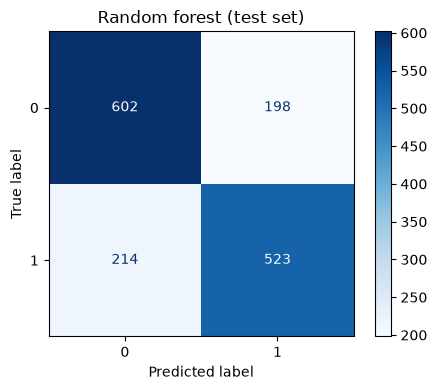

In [16]:
##########################################################
## Final model: evaluate on the fitting data and on test ##
##########################################################
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay  # classification metrics + confusion matrix plot

rf_best_clf = rf_grid_clf.best_estimator_  # best combination, already refit on the fitting data

y_fit_pred  = rf_best_clf.predict(X_fit)   # class predictions on the fitting data (train + val)
y_test_pred = rf_best_clf.predict(X_test)  # class predictions on test, the first time test is used

print('-------------------------------------------------------------------------')
print(f'Random forest {rf_grid_clf.best_params_}')
print('F1        - fit: %.3f, test: %.3f' % (f1_score(y_fit_clf, y_fit_pred),        f1_score(y_test_clf, y_test_pred)))
print('Precision - fit: %.3f, test: %.3f' % (precision_score(y_fit_clf, y_fit_pred), precision_score(y_test_clf, y_test_pred)))
print('Recall    - fit: %.3f, test: %.3f' % (recall_score(y_fit_clf, y_fit_pred),    recall_score(y_test_clf, y_test_pred)))
print('-------------------------------------------------------------------------')

# Confusion matrix on test: rows = actual class, columns = predicted class
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test_clf, y_test_pred, ax=ax, cmap='Blues')
ax.set_title('Random forest (test set)')
plt.tight_layout()
plt.show()

### What we observe

### What we observe

- **Test F1 is 0.717**, with precision 0.725 and recall 0.710
- **The fit-to-test gap is larger than in the earlier run:** F1 falls from 0.774 (fit) to 0.717 (test). The selected `min_samples_leaf=1` lets trees fit individual rows, which is consistent with this gap, though we have not tested it
- **Most of the drop comes from recall** (0.790 to 0.710), while precision falls less (0.758 to 0.725)
- **Precision and recall are now close**, so this forest does not clearly favour one error type

**QUESTION:** The forest's precision and recall are close (0.725 and 0.710). Using the false-positive vs false-negative cost discussion from the EDA notebook, would you move the classification threshold away from 0.5? In which direction, and what would happen to precision and recall?

**QUESTION:** CV could not separate `min_samples_leaf=1` from `min_samples_leaf=10` (both in the top six). Refit with `min_samples_leaf=10` and compare the fit-to-test gap. Which setting would you choose, and why?


### 2.6 Out-of-bag (OOB) error: a quick reminder

- Each tree is trained on a bootstrap sample, which leaves out about **37% of the rows**. Those are the tree's **out-of-bag** rows
- To score a row, we use only the trees that **never saw it**, so the prediction is not inflated by memorization
- Scoring every fitting row this way gives a validation estimate **without a held-out set or a CV loop**
- `oob_score_` reports **accuracy**, which is misleading for this target, so we compute F1 ourselves from `oob_decision_function_`, the OOB class probabilities of every fitting row
- Here we compare three estimates of the same model: the CV F1 from `GridSearchCV`, the OOB F1, and the test F1

In [19]:
##########################################################
## OOB F1 vs CV F1 vs test F1                            ##
##########################################################
# Refit the best combination on the fitting data, this time with oob_score=True
rf_oob_clf = RandomForestClassifier(**rf_grid_clf.best_params_,  # best hyperparameters from GridSearchCV
                                    class_weight='balanced',
                                    oob_score=True,              # keep each row's out-of-bag predictions
                                    random_state=42,
                                    n_jobs=-1)
rf_oob_clf.fit(X_fit, y_fit_clf)

# P(repays) for every fitting row, averaged over the trees that never saw that row
oob_proba = rf_oob_clf.oob_decision_function_[:, 1]
y_fit_oob_pred = (oob_proba >= 0.5).astype(int)  # default 0.5 threshold

print('-------------------------------------------------------------------------')
print(f'OOB accuracy (oob_score_, misleading here): {rf_oob_clf.oob_score_:.3f}')
print(f'OOB F1:                                     {f1_score(y_fit_clf, y_fit_oob_pred):.3f}')
print(f'Mean validation F1 (5-fold CV):             {rf_grid_clf.best_score_:.3f}')
print(f'Test F1:                                    {f1_score(y_test_clf, y_test_pred):.3f}')
print('-------------------------------------------------------------------------')

-------------------------------------------------------------------------
OOB accuracy (oob_score_, misleading here): 0.808
OOB F1:                                     0.656
Mean validation F1 (5-fold CV):             0.655
Test F1:                                    0.717
-------------------------------------------------------------------------


### What we observe

### What we observe

- **OOB F1 (0.656) and CV F1 (0.655) are almost identical.** OOB needed 1 fit, while `GridSearchCV` needed 24 combinations x 5 folds = 120 fits
- **Fit F1 (0.774 in 2.5) is well above OOB F1 (0.656).** The model was trained on the fitting rows, so scoring on them is optimistic. OOB scores each row only with trees that never saw it
- **The fit-to-OOB gap is large, and `min_samples_leaf=1` is a likely contributor.** We have not tested this
- **OOB accuracy (0.808) looks strong but is misleading.** Compare it with the share of non-repayers in the 2.3 class balance print, which is the accuracy of always predicting "does not repay"
- **Test F1 (0.717) is higher than both OOB and CV.** OOB and CV shuffle rows across time, while the test split comes later

**QUESTION:** OOB and CV both estimate performance on rows drawn from the same period as the training data, yet the test F1 is higher than both. Using what you found in the EDA notebook about the class balance and the drift across splits, suggest a reason, and say how you would check it. Why can OOB error not detect a problem like temporal drift?

### 2.7 Feature importance

- **Mean decrease in impurity (MDI):** each split reduces the impurity of the node it splits. A feature's importance is the total reduction it produces across all trees, normalised so the importances sum to 1
- **Dummy columns share a variable's importance.** We sum the importances of the dummies back to the original variable, so `debt_type` appears once
- **Caveat:** MDI favours continuous features with many possible split points, and it is computed on the training rows

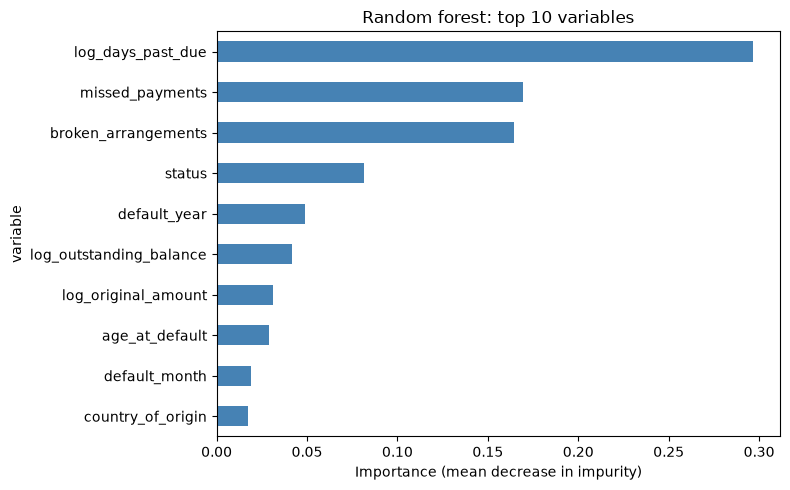

variable
log_days_past_due          0.297
missed_payments            0.169
broken_arrangements        0.164
status                     0.081
default_year               0.049
log_outstanding_balance    0.042
log_original_amount        0.031
age_at_default             0.029
default_month              0.019
country_of_origin          0.017
Name: importance, dtype: float64

In [20]:
##########################################################
## Feature importance, summed per original variable      ##
##########################################################
# Importance of every column of the final forest, from 2.5 (they sum to 1)
importance_df = pd.DataFrame({'feature': feature_cols,
                              'importance': rf_best_clf.feature_importances_})

def original_variable(col):
    """Maps a feature column to the variable it came from.

    Args:
        col (str): Name of a column in feature_cols.

    Returns:
        str: The nominal variable a dummy column was built from
            (e.g. 'debt_type_Credit card' -> 'debt_type'), or col itself
            if it is not a dummy column.
    """
    for nominal in nominal_cols:
        if col.startswith(nominal + '_'):  # dummy names are '<variable>_<category>'
            return nominal
    return col

importance_df['variable'] = importance_df['feature'].apply(original_variable)

# Sum the dummies of each variable and rank, largest first
importance_by_variable = (importance_df.groupby('variable')['importance']
                          .sum().sort_values(ascending=False))

# Top 10 variables as a horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 5))
importance_by_variable.head(10)[::-1].plot(kind='barh', ax=ax, color='steelblue')  # [::-1] puts the largest bar on top
ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_title('Random forest: top 10 variables')
plt.tight_layout()
plt.show()

importance_by_variable.head(10).round(3)

**QUESTIONS:**

- Which three variables carry the most importance? What share of the total do they hold together?
- Compare this ranking with the correlations with the repayment target in the EDA notebook. Do the top variables match? Why could a forest and a correlation pick out the same variables, or different ones?
- `log_days_past_due` and `missed_payments` had a VIF of about 6 in the EDA notebook. How can correlated features affect their importances?
- `status` ranks high. Look at its categories. Is each value known at the moment an account defaults, or could some only be recorded after repayment? What would that mean for using this model on new accounts?
- `default_year` is in the top 10. What does that tell you about drift in this dataset? The test split covers later years, and trees cannot extrapolate beyond the values they saw in training. What does that imply for predictions on later accounts, and how would you check it?
- Where does `log_outstanding_balance` rank? Does that match what you would expect from domain knowledge?
- How many demographic variables are in the top 10? What does that suggest about which information matters for repayment?
- Importance is computed as mean decrease in impurity, on the training rows. What biases could this introduce, and how would you check the ranking another way?
- `default_year` ranks fifth. The test split covers later years than the training data. Trees cannot extrapolate beyond the values they saw during training. What does that imply for the forest's predictions on later accounts, and how would you check it?

## 3. Random Forest for Regression

We now predict **how much** an account repays, `log_repayment_amount`, with the same workflow as in Section 2. What changes:

- **`RandomForestRegressor`:** each tree predicts a number, and the forest averages them
- **No `class_weight`:** the target is continuous, so there are no classes to balance
- **Tuning score:** we tune on **RMSE on the log scale**, as in the KNN notebook. `GridSearchCV` maximises its score, so it reports the **negative** RMSE
- **Final metrics in EUR:** predictions are converted with `np.expm1()` before computing MAE, RMSE and R²
- **OOB score:** for a regressor, `oob_score_` is the R² of the out-of-bag predictions, on the log scale

### 3.1 Defining the target

In [21]:
##########################################################
## Define the target: regression labels per split        ##
##########################################################
# Labels for the regression target, taken from the same original splits
y_train_reg = df_train['log_repayment_amount']  # train labels
y_val_reg   = df_val['log_repayment_amount']    # validation labels
y_test_reg  = df_test['log_repayment_amount']   # test labels (not used until the final evaluation)
y_fit_reg   = df_fit['log_repayment_amount']    # fitting labels (train + val), aligned with X_fit

print(f'y_train_reg: {y_train_reg.shape}, y_val_reg: {y_val_reg.shape}, '
      f'y_test_reg: {y_test_reg.shape}, y_fit_reg: {y_fit_reg.shape}')

y_train_reg: (8894,), y_val_reg: (3090,), y_test_reg: (1537,), y_fit_reg: (11984,)


### 3.2 Tuning with `GridSearchCV`

Same grid and same folds (`kf`) as in Section 2, so the two forests are tuned in the same way.

In [22]:
##########################################################
## Tune the random forest regressor with GridSearchCV    ##
##########################################################
from sklearn.ensemble import RandomForestRegressor  # forest of decision trees for a continuous target

# Same hyperparameter grid as the classifier (24 combinations)
param_grid_reg = {
    'n_estimators': [100, 300],        # number of trees
    'max_depth': [5, 10, 20],          # maximum depth of each tree
    'min_samples_leaf': [1, 10],       # minimum rows in a leaf (pruning)
    'max_features': ['sqrt', 0.3],     # features considered at each split
}

rf_grid_reg = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),  # no class_weight for a continuous target
    param_grid=param_grid_reg,
    scoring='neg_root_mean_squared_error',  # RMSE on the log scale, negated so larger is better
    cv=kf,          # the folds defined in Section 2
    n_jobs=-1,      # use all CPU cores
)
rf_grid_reg.fit(X_fit, y_fit_reg)  # 24 combinations x 5 folds, may take a few minutes

print('Best hyperparameters:', rf_grid_reg.best_params_)
print(f'Best mean validation RMSE (log scale, 5-fold CV): {-rf_grid_reg.best_score_:.3f}')  # undo the negation

# Rename the columns after the data the score is computed on, and flip the sign back to RMSE
rf_cv_results_reg_df = pd.DataFrame(rf_grid_reg.cv_results_)[['param_n_estimators', 'param_max_depth',
                                                              'param_min_samples_leaf', 'param_max_features',
                                                              'mean_test_score', 'std_test_score']].copy()
rf_cv_results_reg_df['mean_val_rmse'] = -rf_cv_results_reg_df['mean_test_score']  # positive RMSE, lower is better
rf_cv_results_reg_df['std_val_rmse']  = rf_cv_results_reg_df['std_test_score']    # spread across the validation folds
rf_cv_results_reg_df = (rf_cv_results_reg_df.drop(columns=['mean_test_score', 'std_test_score'])
                        .sort_values('mean_val_rmse', ascending=True))
rf_cv_results_reg_df

Best hyperparameters: {'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}
Best mean validation RMSE (log scale, 5-fold CV): 1.501


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_val_rmse,std_val_rmse
23,300,20,10,0.3,1.501039,0.021149
15,300,10,10,0.3,1.501738,0.020889
13,300,10,1,0.3,1.502256,0.021710
22,100,20,10,0.3,1.503629,0.020135
14,100,10,10,0.3,1.503758,0.020457
12,100,10,1,0.3,1.504179,0.020511
21,300,20,1,0.3,1.511891,0.020155
17,300,20,1,sqrt,1.517675,0.020855
20,100,20,1,0.3,1.517771,0.019984
19,300,20,10,sqrt,1.519871,0.020504


### What we observe

- **The top six combinations are within 0.003 RMSE of each other** (1.501 to 1.504), while the spread across folds is about 0.02. As with the classifier, the data cannot separate them
- **`max_features=0.3` beats `'sqrt'`** at every depth, and 0.3 is the largest value in the grid
- **`max_depth=5` is clearly the worst** (1.530 to 1.623), so very shallow trees underfit. Depth 10 and 20 tie at the top
- **The gap between `'sqrt'` and 0.3 shrinks as depth grows:** about 0.09 at depth 5, 0.03 at depth 10, and under 0.02 at depth 20
- **At `max_depth=20`, `min_samples_leaf=1` scores worse than 10** (1.512 vs 1.501 with 300 trees), while at depth 10 the two are almost equal. This gap is within the fold-to-fold spread, so it is only a hint
- **`n_estimators` (100 vs 300) changes the score by at most 0.006**, far below the fold-to-fold spread

### 3.3 Final model: evaluation in EUR and OOB

- `rf_best_reg` is the best combination, already refit on the fitting data by `GridSearchCV`
- Test is used for the first time here. Metrics are reported in **EUR** as `fit: %.2f, test: %.2f` pairs
- The OOB estimate comes from one extra fit with `oob_score=True`, and is compared on the **log scale** with the CV RMSE and the test RMSE

In [23]:
##########################################################
## Final model: metrics in EUR, then OOB vs CV vs test   ##
##########################################################
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # regression metrics

def eur_metrics(y_true_log, y_pred_log):
    """Computes MAE, RMSE and R2 on the EUR scale from log-scale values.

    Args:
        y_true_log (pd.Series): True labels on the log scale.
        y_pred_log (np.ndarray): Predictions on the log scale.

    Returns:
        dict: {'mae', 'rmse', 'r2'}, all computed after np.expm1().
    """
    y_true_eur = np.expm1(y_true_log)  # back to EUR
    y_pred_eur = np.expm1(y_pred_log)  # back to EUR
    return {'mae': mean_absolute_error(y_true_eur, y_pred_eur),
            'rmse': np.sqrt(mean_squared_error(y_true_eur, y_pred_eur)),
            'r2': r2_score(y_true_eur, y_pred_eur)}

rf_best_reg = rf_grid_reg.best_estimator_  # best combination, already refit on the fitting data

fit_m  = eur_metrics(y_fit_reg,  rf_best_reg.predict(X_fit))   # metrics on the fitting data (train + val)
test_m = eur_metrics(y_test_reg, rf_best_reg.predict(X_test))  # metrics on test, the first time test is used

print('-------------------------------------------------------------------------')
print(f'Random forest regressor {rf_grid_reg.best_params_}')
print('MAE  - fit: %.2f, test: %.2f' % (fit_m['mae'],  test_m['mae']))
print('RMSE - fit: %.2f, test: %.2f' % (fit_m['rmse'], test_m['rmse']))
print('R-2  - fit: %.3f, test: %.3f' % (fit_m['r2'],   test_m['r2']))
print('-------------------------------------------------------------------------')

# OOB: refit the best combination with oob_score=True
rf_oob_reg = RandomForestRegressor(**rf_grid_reg.best_params_,  # best hyperparameters from GridSearchCV
                                   oob_score=True,              # keep each row's out-of-bag predictions
                                   random_state=42,
                                   n_jobs=-1)
rf_oob_reg.fit(X_fit, y_fit_reg)

# RMSE on the log scale, so the three estimates are comparable
oob_rmse_log  = np.sqrt(mean_squared_error(y_fit_reg, rf_oob_reg.oob_prediction_))  # OOB predictions use only trees that never saw the row
test_rmse_log = np.sqrt(mean_squared_error(y_test_reg, rf_best_reg.predict(X_test)))

print(f'OOB R-2 (log scale, oob_score_):         {rf_oob_reg.oob_score_:.3f}')
print(f'OOB RMSE (log scale):                    {oob_rmse_log:.3f}')
print(f'Mean validation RMSE (log, 5-fold CV):   {-rf_grid_reg.best_score_:.3f}')
print(f'Test RMSE (log scale):                   {test_rmse_log:.3f}')

-------------------------------------------------------------------------
Random forest regressor {'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}
MAE  - fit: 23.71, test: 66.27
RMSE - fit: 73.02, test: 148.13
R-2  - fit: 0.188, test: -0.090
-------------------------------------------------------------------------
OOB R-2 (log scale, oob_score_):         0.375
OOB RMSE (log scale):                    1.496
Mean validation RMSE (log, 5-fold CV):   1.501
Test RMSE (log scale):                   2.085


### What we observe

- **On the EUR scale, test R² is still negative (-0.090)**, so the forest does worse than always predicting the mean amount. It is less negative than the linear regression (-0.178) and KNN (-0.218) in our earlier runs. Those runs came before the reinstall, so they must be re-run before this comparison is trusted
- **Fit R² is only 0.188.** Even on the data it was trained on, the forest explains little variance in EUR
- **Test MAE (66.27) and RMSE (148.13) are far above the fit values** (23.71 and 73.02), a clear fit-to-test gap
- **On the log scale, OOB RMSE (1.496) and CV RMSE (1.501) agree closely**, as they did for the classifier. OOB R² is 0.375
- **Test RMSE on the log scale (2.085) is much higher than both.** OOB and CV shuffle rows across time, while the test split comes later, and the EDA notebook found that `repayment_amount` drifts over time. We have not shown that drift is the cause
- **The forest is fit on the log scale, but R² in EUR is dominated by a few large amounts.** `expm1()` stretches errors on large predictions

**QUESTIONS:**

- Test R² is negative on the EUR scale, while OOB R² is 0.375 on the log scale. Why can the same model look good on one scale and bad on the other?
- OOB and CV RMSE (about 1.50) are far below the test RMSE (2.085) on the log scale. What could explain the gap? How would you check whether drift is the cause?
- Both the fit R² (0.188) and the test R² are low in EUR. Would a better algorithm fix this, or is the problem in how the target is defined? Remember that most accounts repay nothing
- Compare with the linear regression and KNN. Does the forest improve on them? By how much, and does that justify its extra cost?

### 3.4 Feature importance

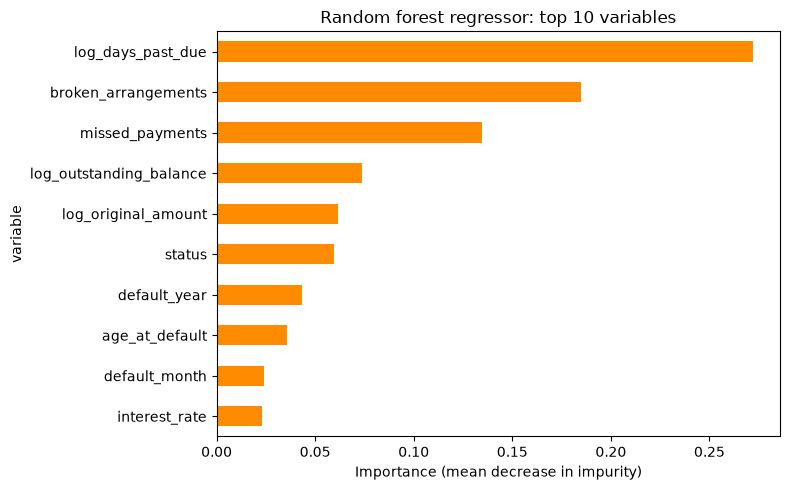

variable
log_days_past_due          0.272
broken_arrangements        0.185
missed_payments            0.135
log_outstanding_balance    0.074
log_original_amount        0.062
status                     0.060
default_year               0.043
age_at_default             0.036
default_month              0.024
interest_rate              0.023
Name: importance, dtype: float64

In [24]:
##########################################################
## Feature importance of the regressor, per variable     ##
##########################################################
# Importance of every column of the final regressor (they sum to 1)
importance_reg_df = pd.DataFrame({'feature': feature_cols,
                                  'importance': rf_best_reg.feature_importances_})

# original_variable() comes from 2.7: it maps a dummy column back to its nominal variable
importance_reg_df['variable'] = importance_reg_df['feature'].apply(original_variable)

# Sum the dummies of each variable and rank, largest first
importance_reg_by_variable = (importance_reg_df.groupby('variable')['importance']
                              .sum().sort_values(ascending=False))

# Top 10 variables as a horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 5))
importance_reg_by_variable.head(10)[::-1].plot(kind='barh', ax=ax, color='darkorange')  # [::-1] puts the largest bar on top
ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_title('Random forest regressor: top 10 variables')
plt.tight_layout()
plt.show()

importance_reg_by_variable.head(10).round(3)

**QUESTIONS:**

- Which three variables carry the most importance for the regressor? Compare with the classifier's ranking in 2.7. What changes, and what stays the same?
- `log_outstanding_balance` and `log_original_amount` rank higher for the regressor than for the classifier. Why might the size of the debt matter more for predicting **how much** an account repays than for predicting **whether** it repays?
- Does the ranking match what you would expect from domain knowledge? Where would it surprise a collection agency?
- Which variables from the EDA notebook (correlations, VIF) show up again here? Which do not?
- Importance is computed on the fitting data. How could you check the ranking on the test split?

## 4. Comparing the Models

All numbers are on the **same test split**.

**Classification (`repayment_probability`), test F1**

| Model | Test F1 |
|---|---|
| Logistic regression, no regularisation | 0.679 |
| Logistic regression, L2 (C=0.2) | 0.681 |
| KNN, k=1, Manhattan (validation-selected) | 0.446 |
| KNN, k=3, Manhattan (CV-selected) | 0.408 |
| Random forest | 0.717 |

**Regression (`log_repayment_amount`), test metrics in EUR**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear regression | 69.56 | 154.00 | -0.178 |
| Ridge (alpha=1) | 69.56 | 154.02 | -0.179 |
| KNN, k=50, Manhattan | 71.03 | 156.56 | -0.218 |
| Random forest | 66.27 | 148.13 | -0.090 |

**NOTE: The models were not set up identically for pedagogy puporses:**

- The logistic regression and the random forest use `class_weight='balanced'`, and KNN has no such option
- The logistic regression left out `gender`, and KNN and the forest used all features
- The linear and logistic regressions were fit on train only. KNN and the forest were refit on train + val

**QUESTIONS:**

- Which model wins on classification, and by how much? Is the gap between the forest and the logistic regression large enough to matter, given a test set of about 1,500 accounts?
- The two classification models with similar F1 can make different kinds of errors. How would you check this, and why would the collection agency care?
- KNN scores far below the other two models on classification. Name two reasons, thinking about the curse of dimensionality and class imbalance
- On regression, all three models have a negative R² in EUR. Does a better algorithm fix that, or is the problem in how the target is defined? Remember that most accounts repay nothing
- The forest has the smallest errors on regression, but it needs tuning and many trees. When would a simpler model be the better choice?
- The EDA notebook showed that `repayment_amount` drifts over time. Which of the three models would you expect to suffer most from it, and how would you test it?
- A collection agency asks which model they should use. Weigh performance, interpretability, speed of prediction and what happens as new accounts arrive

## 5. SMOTE

In this notebook we handled the 75/25 class imbalance with `class_weight='balanced'`. **SMOTE** is an alternative: it creates synthetic examples of the minority class (repayers) by interpolating between existing ones, so the model trains on more balanced data. Your task is to try it and compare.

![SMOTE: synthetic minority examples are created between a minority point and its neighbours](img/smote.png)

**Tasks**

1. Install and import `SMOTE` from the `imbalanced-learn` package (`pip install imbalanced-learn`)
2. Tune a random forest on SMOTE-resampled data, **without** `class_weight`, using the same grid and the same folds (`kf`) as in 2.4
3. Evaluate the best model on test and compare F1, precision, recall and the confusion matrix with the class-weight forest from 2.5

**Hints**

- **Do not resample the whole fitting set before cross-validation.** The synthetic rows would be built from rows that later end up in the validation fold, which is leakage, and it inflates the CV score
- Resampling must happen **inside each fold, on the train part only**. Put `SMOTE` and the forest in an `imblearn.pipeline.Pipeline`, and pass that pipeline to `GridSearchCV`
- Hyperparameters of a step in a pipeline are named `<step name>__<parameter>`, for example `rf__max_depth`
- Never resample validation or test rows
- SMOTE interpolates between rows, so think about what that does to binary columns such as the one-hot dummies

**Questions**

- Does SMOTE beat `class_weight='balanced'`? Is the difference larger than the spread across CV folds?
- How do precision and recall change? Which approach would you give to the collection agency?
- What goes wrong if you apply SMOTE before the cross-validation split? Try it on purpose and compare the CV F1 with the test F1
- Why is SMOTE applied only to the training data, and never to the test data?